# Ускоренные методы

In [1]:
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import minimize

matplotlib.rcParams.update({
    "figure.figsize": (12, 5), "legend.fontsize": 10, "axes.labelsize": 13,
    "axes.titlesize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11, "lines.linewidth": 1.8,
})
np.set_printoptions(precision=4, suppress=True)

In [2]:
class Oracle:
    '''Обёртка над f и grad f со счётчиками вызовов.'''
    def __init__(self, f, gradf):
        self._f, self._g = f, gradf
        self.nf = self.ng = 0
    def f(self, x):
        self.nf += 1; return self._f(x)
    def gradf(self, x):
        self.ng += 1; return self._g(x)


def slack(fx):
    """Допуск на ошибки округления в сравнениях значений f."""
    return 10 * np.finfo(float).eps * max(1.0, abs(fx))


class Method:
    '''Общая часть всех методов: история и критерий остановки.
    history: (x, время, вызовы f, вызовы grad, параметр шага);  f_hist: значения f(x_k) (контроль точности, в счётчики не входит).
    Остановка: f(x_k) − fstar ≤ tol, если задано fstar, иначе ‖∇f(x_k)‖ ≤ tol.'''
    def __init__(self, name=None):
        self.name = name; self.history = []; self.f_hist = []; self.restarts = []

    def _start(self, x0, f, gradf):
        self.oracle = Oracle(f, gradf); self.t0 = time.time()
        x = np.array(x0, dtype=float)
        self.history = [(x, 0.0, 0, 0, np.nan)]; self.f_hist = [f(x)]; self.restarts = []
        return x

    def _record(self, x, f, step):
        self.history.append((x, time.time() - self.t0, self.oracle.nf, self.oracle.ng, step))
        self.f_hist.append(f(x))

    @staticmethod
    def _done(fx, g, tol, fstar):
        return (fx - fstar <= tol) if fstar is not None else (np.linalg.norm(g) <= tol)


class ConstantStepSize:
    def __init__(self, alpha): self.alpha = alpha
    def __call__(self, x, h, k, *a, **kw): return self.alpha


class Backtracking:
    '''Армихо с дроблением; warm=True: стартуем с удвоенного предыдущего шага.'''
    def __init__(self, c=1e-4, rho=0.5, alpha0=1.0, warm=True):
        self.c, self.rho, self.alpha0, self.warm = c, rho, alpha0, warm
        self.reset()
    def reset(self):
        self.prev = None; self.cache = None
    def __call__(self, x, h, k, gradf, f, g=None):
        alpha = self.alpha0 if (not self.warm or self.prev is None) else 2 * self.prev
        c = self.cache
        fx = c[1] if c is not None and np.array_equal(c[0], x) else f(x)
        hg = g @ h if g is not None else -(h @ h)     # <grad f(x), h>
        while (fa := f(x + alpha * h)) > fx + self.c * alpha * hg + slack(fx):
            alpha *= self.rho
        self.prev = alpha; self.cache = (x + alpha * h, fa)
        return alpha


class GradientDescent(Method):
    '''x_{k+1} = x_k − α_k P ∇f(x_k); precond: функция g ↦ P g (по умолчанию P = I).'''
    def __init__(self, StepSizeChoice, name=None, precond=None):
        super().__init__(name); self.StepSizeChoice, self.precond = StepSizeChoice, precond

    def solve(self, x0, f, gradf, tol=1e-6, max_iter=10000, fstar=None):
        x = self._start(x0, f, gradf); o = self.oracle
        if hasattr(self.StepSizeChoice, "reset"): self.StepSizeChoice.reset()
        for k in range(max_iter):
            g = o.gradf(x)
            if self._done(self.f_hist[-1], g, tol, fstar): break
            h = -g if self.precond is None else -self.precond(g)
            alpha = self.StepSizeChoice(x, h, k, o.gradf, o.f, g=g)
            x = x + alpha * h
            self._record(x, f, alpha)
        return x


class HeavyBall(Method):
    '''x_{k+1} = x_k − α ∇f(x_k) + β (x_k − x_{k−1}).'''
    def __init__(self, alpha, beta, name=None):
        super().__init__(name); self.alpha, self.beta = alpha, beta

    def solve(self, x0, f, gradf, tol=1e-6, max_iter=10000, fstar=None):
        x = self._start(x0, f, gradf); x_prev = x.copy(); o = self.oracle
        for k in range(max_iter):
            g = o.gradf(x)
            if self._done(self.f_hist[-1], g, tol, fstar): break
            x, x_prev = x - self.alpha * g + self.beta * (x - x_prev), x
            self._record(x, f, self.alpha)
            if not np.isfinite(self.f_hist[-1]): break
        return x


class Nesterov(Method):
    '''Ускоренный метод Нестерова с шагом 1/(L + ρ):  y_0 = x_0,  x_{k+1} = y_k − ∇F(y_k)/(L + ρ),  y_{k+1} = x_{k+1} + β_k (x_{k+1} − x_k).
    mu=None: выпуклая форма β_k = k/(k+3);  mu задано: β = (√(L+ρ) − √(μ+ρ)) / (√(L+ρ) + √(μ+ρ)).
    restart: None | "f" (рост F) | "g" (по градиенту) | "fixed" (каждые K итераций).
    rho > 0: минимизируется F = f + ρ/2‖x − center‖² (центр по умолчанию x_0); f_hist по-прежнему хранит исходную f.'''
    def __init__(self, L, mu=None, restart=None, K=None, rho=0.0, center=None, name=None):
        super().__init__(name)
        self.L, self.mu, self.restart, self.K, self.rho, self.center = L, mu, restart, K, rho, center

    def solve(self, x0, f, gradf, tol=1e-6, max_iter=10000, fstar=None):
        x = self._start(x0, f, gradf); o = self.oracle
        c = x.copy() if self.center is None else self.center; rho = self.rho
        F = (lambda z: o.f(z) + rho / 2 * (z - c) @ (z - c)) if rho else o.f
        G = (lambda z: o.gradf(z) + rho * (z - c)) if rho else o.gradf
        Lr = self.L + rho
        beta_sc = None if self.mu is None else \
            (np.sqrt(Lr) - np.sqrt(self.mu + rho)) / (np.sqrt(Lr) + np.sqrt(self.mu + rho))
        y = x.copy(); k = 0; Fx = F(x) if self.restart == "f" else None
        for it in range(max_iter):
            if fstar is not None and self.f_hist[-1] - fstar <= tol: break
            g = G(y)
            if fstar is None and np.linalg.norm(g) <= tol: break
            x_new = y - g / Lr
            Fn = F(x_new) if self.restart == "f" else None
            if (self.restart == "f" and Fn > Fx) or (self.restart == "g" and g @ (x_new - x) > 0) \
                    or (self.restart == "fixed" and k + 1 >= self.K):
                self.restarts.append(it); k = 0; y = x_new.copy(); beta = 0.0
            else:
                beta = beta_sc if beta_sc is not None else k / (k + 3)
                y = x_new + beta * (x_new - x); k += 1
            x, Fx = x_new, Fn
            self._record(x, f, beta)
        return x


class WolfeSearch:
    """Бисекция: (W1) нарушено -> уменьшаем, (W2) нарушено -> увеличиваем.
    strong=True: вместо (W2) проверяется сильное условие |phi'(a)| <= c2 |phi'(0)|."""
    def __init__(self, c1=1e-4, c2=0.9, alpha0=1.0, max_it=60, warm=False, strong=False):
        self.c1, self.c2, self.a0, self.max_it, self.warm, self.strong = c1, c2, alpha0, max_it, warm, strong
        self.prev = None; self.cache = None
    def reset(self): self.prev = None; self.cache = None
    def __call__(self, x, h, k, gradf, f, g=None):
        lb, ub = 0.0, np.inf
        a = self.a0 if (not self.warm or self.prev is None) else 2 * self.prev
        c = self.cache
        fx = c[1] if c is not None and np.array_equal(c[0], x) else f(x)
        d0 = g @ h if g is not None else -(h @ h)          # phi'(0) = <grad f(x), h>
        for _ in range(self.max_it):
            fa = f(x + a * h)
            if fa > fx + self.c1 * a * d0 + slack(fx):
                ub = a; a = 0.5 * (lb + ub); continue
            da = gradf(x + a * h) @ h
            if da < self.c2 * d0:                          # шаг слишком мал: функция ещё круто убывает
                lb = a; a = 2 * lb if np.isinf(ub) else 0.5 * (lb + ub)
            elif self.strong and da > -self.c2 * d0:      # шаг слишком велик: функция уже круто растёт
                ub = a; a = 0.5 * (lb + ub)
            else:
                break
        self.prev = a; self.cache = (x + a * h, fa)
        return a


class ConjugateGradients(Method):
    """Нелинейные сопряжённые градиенты; шаг выбирается правилом Вольфа из недели 10 (сильные условия, параметр c2).
    beta: "FR" | "PR" | "PR+";  restart: None | "n" (каждые n итераций) | "powell" (|<g_k, g_{k−1}>| ≥ 0.2‖g_k‖²)."""
    def __init__(self, beta="FR", restart=None, c2=0.1, name=None):
        super().__init__(name); self.beta, self.restart, self.c2 = beta, restart, c2

    def solve(self, x0, f, gradf, tol=1e-6, max_iter=10000, fstar=None):
        x = self._start(x0, f, gradf); o = self.oracle; n = len(x)
        ls = WolfeSearch(c1=1e-4, c2=self.c2, strong=True, warm=True)
        g = o.gradf(x); d = -g; self.cos = []
        for it in range(max_iter):
            if self._done(self.f_hist[-1], g, tol, fstar): break
            self.cos.append(-(g @ d) / (np.linalg.norm(g) * np.linalg.norm(d)))
            a = ls(x, d, it, o.gradf, o.f, g=g)
            x = x + a * d
            gnew = o.gradf(x)
            if self.beta == "FR":   b = (gnew @ gnew) / (g @ g)
            elif self.beta == "PR": b = gnew @ (gnew - g) / (g @ g)
            else:                   b = max(0.0, gnew @ (gnew - g) / (g @ g))
            rst = (self.restart == "n" and (it + 1) % n == 0) or \
                  (self.restart == "powell" and abs(gnew @ g) >= 0.2 * (gnew @ gnew))
            if rst or (self.beta == "PR+" and b == 0.0): self.restarts.append(it)
            d = -gnew + (0.0 if rst else b) * d
            g = gnew
            self._record(x, f, a)
        return x


class AdaptiveAcceleratedGD(Method):
    """Ускоренный AdGD (Malitsky, Mishchenko, 2020, arXiv:1910.09529, Algorithm 2): оценивает L и μ по секущим, без параметров."""
    def __init__(self, lam0=1e-6, Lam0=1e-6, name=None):
        super().__init__(name); self.lam0, self.Lam0 = lam0, Lam0; self.Lam_hist = []

    def solve(self, x0, f, gradf, tol=1e-6, max_iter=10000, fstar=None):
        x_prev = self._start(x0, f, gradf); o = self.oracle
        g_prev = o.gradf(x_prev)
        lam, Lam, th, Th = self.lam0, self.Lam0, np.inf, np.inf
        x = x_prev - lam * g_prev; y = x.copy()
        self._record(y, f, lam); self.Lam_hist = [Lam]
        for k in range(max_iter):
            g = o.gradf(x)
            if self._done(self.f_hist[-1], g, tol, fstar): break
            dx, dg = np.linalg.norm(x - x_prev), np.linalg.norm(g - g_prev)
            lam_new = min(np.sqrt(1 + th / 2) * lam, dx / (2 * dg) if dg > 0 else np.inf)
            Lam_new = min(np.sqrt(1 + Th / 2) * Lam, dg / (2 * dx) if dx > 0 else np.inf)
            if not np.isfinite(lam_new): lam_new = lam
            if not np.isfinite(Lam_new): Lam_new = Lam
            beta = (np.sqrt(1 / lam_new) - np.sqrt(Lam_new)) / (np.sqrt(1 / lam_new) + np.sqrt(Lam_new))
            y_new = x - lam_new * g
            x_prev, g_prev = x, g
            x = y_new + beta * (y_new - y); y = y_new
            th, Th, lam, Lam = lam_new / lam, Lam_new / Lam, lam_new, Lam_new
            self.Lam_hist.append(Lam)
            self._record(y, f, lam)
        return y


def first_hit(m, fstar, tol):
    '''Первая итерация, на которой f(x_k) − fstar ≤ tol (∞, если не достигнуто).'''
    idx = np.nonzero(np.array(m.f_hist) - fstar <= tol)[0]
    return idx[0] if len(idx) else np.inf


class LinearCG(Method):
    """Сопряжённые градиенты для f(x) = ½xᵀAx − bᵀx: r_k = Ax_k − b, p_k = −r_k + β_k p_{k−1}, точный шаг."""
    def __init__(self, A, b, name=None):
        super().__init__(name); self.A, self.b = A, b

    def solve(self, x0, f, gradf, tol=1e-12, max_iter=10000, fstar=None):
        x = self._start(x0, f, gradf); A = self.A
        r = A @ x - self.b; p = -r
        for k in range(max_iter):
            if np.linalg.norm(r) <= tol * np.linalg.norm(self.b): break
            Ap = A @ p; alpha = (r @ r) / (p @ Ap)
            x = x + alpha * p; r_new = r + alpha * Ap
            beta = (r_new @ r_new) / (r @ r)
            p = -r_new + beta * p; r = r_new
            self._record(x, f, alpha)
        return x


class NAGFree(Method):
    """Метод Нестерова с оценкой μ по ходу работы (Cavalcanti, Lessard, Wilson, 2025, arXiv:2506.13033, Algorithm 1).
    β_t берётся по текущей оценке m_t, а m_t обновляется бегущим минимумом секущей кривизны
    c_{t+1} = ‖∇f(x_{t+1}) − ∇f(x_t)‖ / ‖x_{t+1} − x_t‖ ∈ [μ, L]. Дополнительных вызовов оракула нет."""
    def __init__(self, L, seed=0, name=None):
        super().__init__(name); self.L, self.seed = L, seed; self.m_hist = []

    def solve(self, x0, f, gradf, tol=1e-6, max_iter=10000, fstar=None):
        y = self._start(x0, f, gradf); o = self.oracle; L = self.L
        rng = np.random.default_rng(self.seed)
        x = y.copy(); z = y + 1e-6 * rng.random(y.shape)               # пробная точка для m_0
        g = o.gradf(x)
        m = min(max(np.linalg.norm(g - o.gradf(z)) / np.linalg.norm(x - z), L * 1e-14), L)
        self.m_hist = []
        for t in range(max_iter):
            if self._done(self.f_hist[-1], g, tol, fstar): break
            y_new = x - g / L
            beta = (np.sqrt(L) - np.sqrt(m)) / (np.sqrt(L) + np.sqrt(m))
            x_new = y_new + beta * (y_new - y)
            g_new = o.gradf(x_new); dx = np.linalg.norm(x_new - x)
            if dx > 0:
                m = max(min(m, np.linalg.norm(g_new - g) / dx), L * 1e-14)
            x, y, g = x_new, y_new, g_new
            self.m_hist.append(m)
            self._record(y, f, beta)
        return y

## 1. Квадратичная функция: геометрия обусловленности

Пусть $f(x) = \frac12x^\top Ax$, $A\succ0$, $\mu = \lambda_{\min}(A)$, $L = \lambda_{\max}(A)$. В примерах ниже $f(x) = x_1^2 + \gamma x_2^2$, то есть $\mu = 2$, $L = 2\gamma$, $\kappa = \gamma$. Линии уровня являются эллипсами с отношением
полуосей $\sqrt\kappa$. Антиградиент перпендикулярен линии уровня и при большом $\kappa$ направлен почти поперёк вытянутого
эллипса, поэтому GD идёт зигзагом. На рисунке ниже GD с оптимальным шагом $\alpha = \frac2{L+\mu}$.

**Утверждение 1 (GD на квадратичной функции).** При шаге $\alpha$ ошибка равна $x_k - x^* = (I - \alpha A)^k(x_0 - x^*)$ и
$\|x_k - x^*\|\le\max_{\lambda\in[\mu, L]}|1 - \alpha\lambda|^k\,\|x_0 - x^*\|$. Минимум по $\alpha$ достигается при $\alpha = \frac2{L+\mu}$ и равен
$\bigl(\frac{\kappa - 1}{\kappa + 1}\bigr)^k$. При $\alpha = \frac1L$ получаем $\bigl(1 - \frac1\kappa\bigr)^k$.

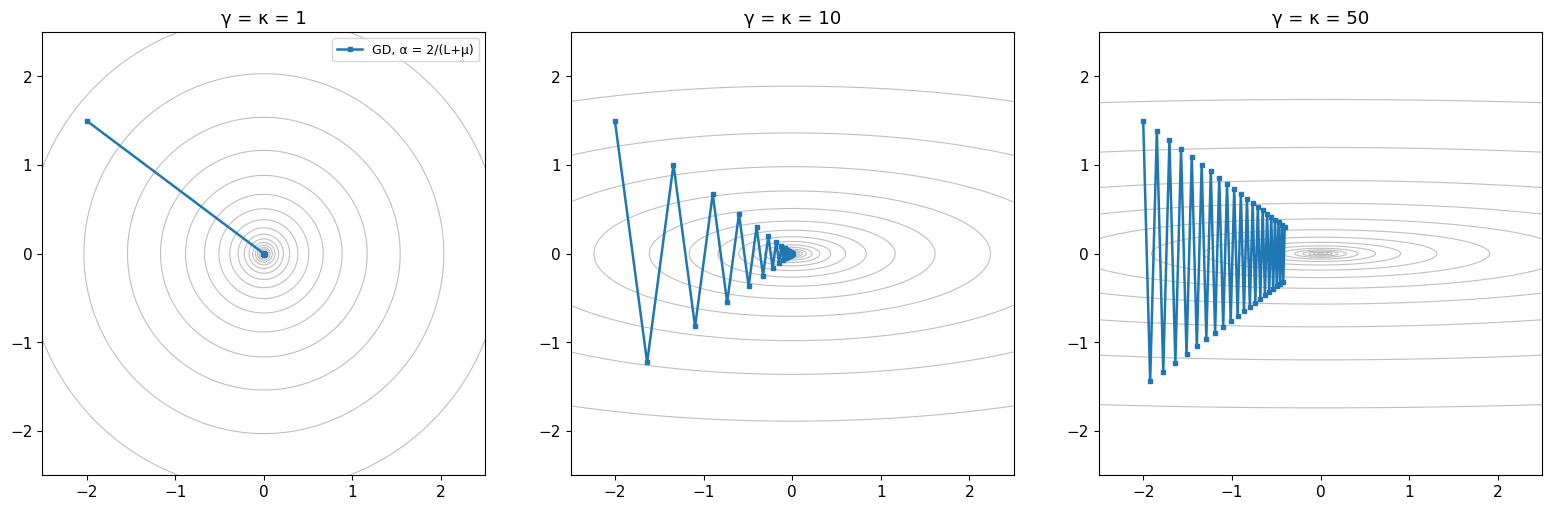

In [3]:
def quad2(gamma):
    """f(x) = x_1² + γ x_2² = ½ xᵀAx,  A = diag(2, 2γ)."""
    A = np.diag([2.0, 2.0 * gamma])
    return A, (lambda x: 0.5 * x @ A @ x), (lambda x: A @ x)

def path(m):
    return np.array([r[0] for r in m.history])

def levels(ax, A, lim=2.5):
    g = np.linspace(-lim, lim, 300); XX, YY = np.meshgrid(g, g)
    Z = 0.5 * (A[0, 0] * XX ** 2 + 2 * A[0, 1] * XX * YY + A[1, 1] * YY ** 2)
    ax.contour(XX, YY, Z, levels=np.geomspace(1e-3, Z.max(), 18), colors="0.75", linewidths=0.8)
    ax.set_aspect("equal"); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
x0q = np.array([-2.0, 1.5])
for ax, kap in zip(axes, [1, 10, 50]):
    A, fq, gq = quad2(kap); levels(ax, A)
    m = GradientDescent(ConstantStepSize(2 / (2 * kap + 2)), name="GD, α = 2/(L+μ)")
    m.solve(x0q, fq, gq, max_iter=40, fstar=-np.inf)
    ax.plot(*path(m).T, "s-", ms=3, label=m.name); ax.set_title(f"γ = κ = {kap}")
axes[0].legend(fontsize=9); plt.tight_layout(); plt.show()

### 1.1. Тяжёлый шарик: зависимость от числа обусловленности

**Метод тяжёлого шарика** (Поляк):
$$
\boxed{\;x_{k+1} = x_k - \alpha\nabla f(x_k) + \beta\,(x_k - x_{k-1})\;}
$$
Для квадратичной функции с параметрами
$\alpha = \frac4{(\sqrt L + \sqrt\mu)^2}$, $\beta = \Bigl(\frac{\sqrt L - \sqrt\mu}{\sqrt L + \sqrt\mu}\Bigr)^2$ ошибка убывает со скоростью $q = \frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}$ вместо $\frac{\kappa - 1}{\kappa + 1}$ у GD,
то есть число итераций растёт как $\sqrt\kappa$, а не как $\kappa$. На неквадратичной функции глобальной сходимости тяжёлого шарика нет.

Проверим на квадратичной задаче размерности $50$ со спектром от $1$ до $\kappa$.

κ =   1e+01:  GD       39   тяжёлый шарик     17
κ =   1e+02:  GD      401   тяжёлый шарик     64
κ =   1e+03:  GD     4099   тяжёлый шарик    226
κ =   1e+04:  GD    41643   тяжёлый шарик    784
κ =   1e+05:  GD   421430   тяжёлый шарик   2691


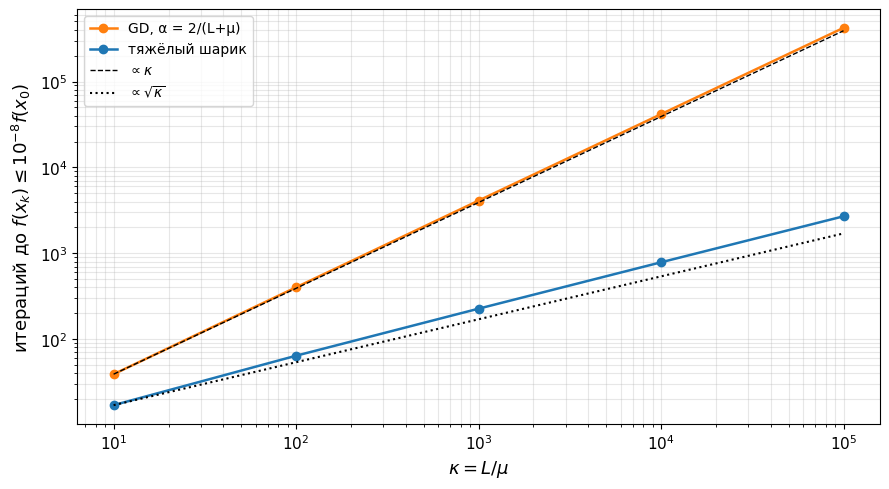

In [4]:
rng = np.random.default_rng(0)
n_sw = 50
Q, _ = np.linalg.qr(rng.standard_normal((n_sw, n_sw)))
def hb_params(L, mu):
    return 4 / (np.sqrt(L) + np.sqrt(mu)) ** 2, ((np.sqrt(L) - np.sqrt(mu)) / (np.sqrt(L) + np.sqrt(mu))) ** 2

kappas = [1e1, 1e2, 1e3, 1e4, 1e5]; rows = []
for kap in kappas:
    d = np.logspace(0, np.log10(kap), n_sw); A = Q @ np.diag(d) @ Q.T; A = (A + A.T) / 2
    fq_, gq_ = (lambda x, A=A: 0.5 * x @ A @ x), (lambda x, A=A: A @ x)
    x0_ = Q @ np.ones(n_sw); tol_ = 1e-8 * fq_(x0_)
    row = []
    for m in [GradientDescent(ConstantStepSize(2 / (kap + 1))), HeavyBall(*hb_params(kap, 1.0))]:
        m.solve(x0_, fq_, gq_, tol=tol_, max_iter=2_000_000, fstar=0.0); row.append(len(m.history) - 1)
    rows.append(row); print(f"κ = {kap:7.0e}:  GD {row[0]:8d}   тяжёлый шарик {row[1]:6d}")
rows = np.array(rows, dtype=float); kappas = np.array(kappas)
fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(kappas, rows[:, 0], "o-", color="C1", label="GD, α = 2/(L+μ)")
ax.loglog(kappas, rows[:, 1], "o-", color="C0", label="тяжёлый шарик")
ax.loglog(kappas, rows[0, 0] * kappas / kappas[0], "k--", lw=1, label=r"$\propto\kappa$")
ax.loglog(kappas, rows[0, 1] * np.sqrt(kappas / kappas[0]), "k:", lw=1.5, label=r"$\propto\sqrt{\kappa}$")
ax.set_xlabel(r"$\kappa = L/\mu$"); ax.set_ylabel(r"итераций до $f(x_k)\leq 10^{-8}f(x_0)$"); ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

### 1.2. Траектории при $\kappa = 10$

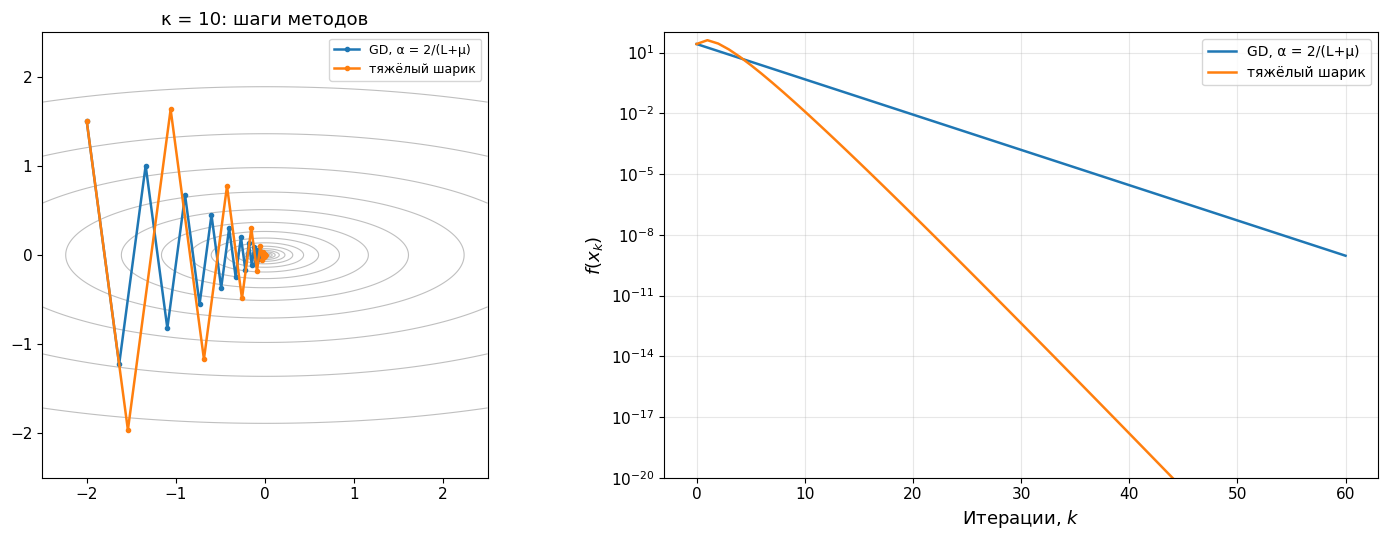

In [8]:
kap = 10; A, fq, gq = quad2(kap); L_, mu_ = 2.0 * kap, 2.0
ms0 = [GradientDescent(ConstantStepSize(2 / (L_ + mu_)), name="GD, α = 2/(L+μ)"),
       HeavyBall(*hb_params(L_, mu_), name="тяжёлый шарик")]
for m in ms0:
    m.solve(x0q, fq, gq, max_iter=60, fstar=-np.inf)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

levels(axes[0], A)
for m in ms0:
    axes[0].plot(*path(m)[:25].T, "o-", ms=3, label=m.name)
axes[0].legend(fontsize=9)
axes[0].set_title("κ = 10: шаги методов")

for m in ms0:
    axes[1].semilogy(np.maximum(m.f_hist, 1e-30), label=m.name)
axes[1].set_ylim(1e-20, 1e2)
axes[1].set_xlabel("Итерации, $k$")
axes[1].set_ylabel("$f(x_k)$")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout(); plt.show()

### 1.3. Ошибка в оценке констант

**Метод Нестерова**:
$$
\boxed{\begin{aligned}
x_{k+1} &= y_k - \tfrac1L\nabla f(y_k),\\
y_{k+1} &= x_{k+1} + \beta_k\,(x_{k+1} - x_k),
\end{aligned}}\qquad y_0 = x_0 .
$$
В сильно выпуклой форме $\beta_k\equiv\beta = \frac{\sqrt L - \sqrt\mu}{\sqrt L + \sqrt\mu}$, и метод гарантирует $O\bigl((1 - 1/\sqrt\kappa)^k\bigr)$. В выпуклой форме $\beta_k = \frac k{k+3}$ и гарантия $O\bigl(LR^2/k^2\bigr)$.

Параметры обоих ускоренных методов считаются по $L$ и $\mu$, а их на практике знают приближённо. На той же задаче ($\kappa = 10$)
подставим в формулы для $\alpha$ и $\beta$ оценки $\tilde L$ и $\tilde\mu$, ошибочные в полтора-два раза.

тяжёлый шарик
   точные L, μ             : 30
   μ̃ = 2μ (μ завышено)    : 55
   μ̃ = μ/2 (μ занижено)   : 44
   L̃ = 0.7L (L занижено)  : inf
   L̃ = 1.5L (L завышено)  : 33
Нестеров, сильно выпуклая форма
   точные L, μ             : 46
   μ̃ = 2μ (μ завышено)    : 79
   μ̃ = μ/2 (μ занижено)   : 50
   L̃ = 0.7L (L занижено)  : 92
   L̃ = 1.5L (L завышено)  : 58


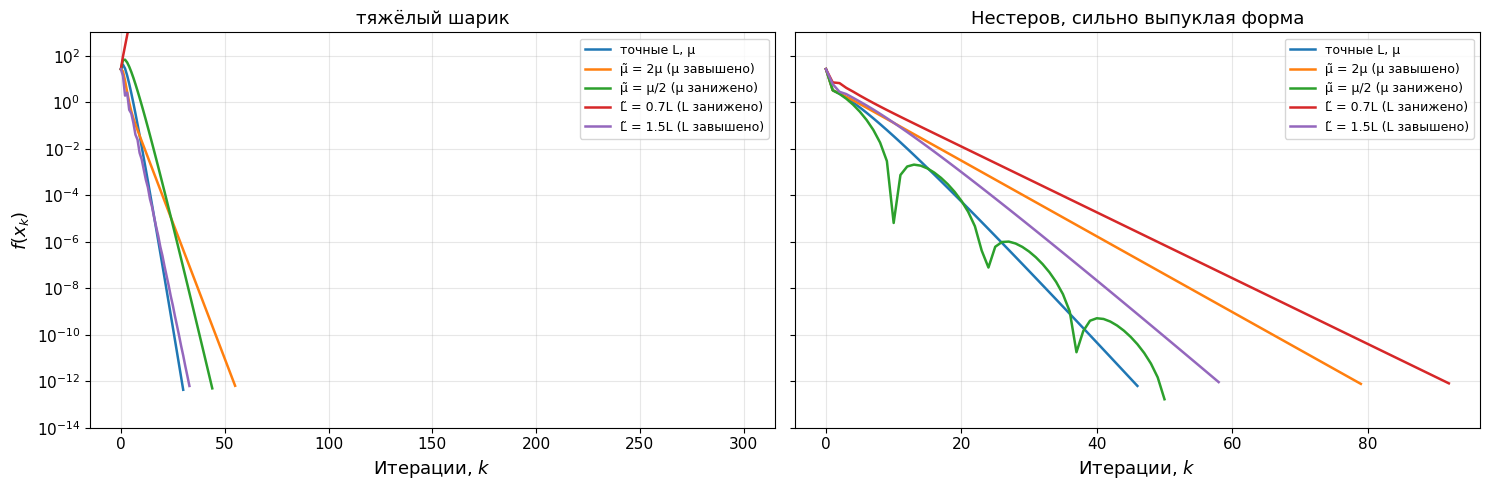

In [6]:
cases = [(L_, mu_, "точные L, μ"), (L_, 2 * mu_, "μ̃ = 2μ (μ завышено)"), (L_, mu_ / 2, "μ̃ = μ/2 (μ занижено)"),
         (0.7 * L_, mu_, "L̃ = 0.7L (L занижено)"), (1.5 * L_, mu_, "L̃ = 1.5L (L завышено)")]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, title, make in [(axes[0], "тяжёлый шарик", lambda Lt, mt, nm: HeavyBall(*hb_params(Lt, mt), name=nm)),
                        (axes[1], "Нестеров, сильно выпуклая форма", lambda Lt, mt, nm: Nesterov(Lt, mu=mt, name=nm))]:
    print(title)
    for Lt, mt, nm in cases:
        m = make(Lt, mt, nm); m.solve(x0q, fq, gq, tol=1e-12, max_iter=300, fstar=0.0)
        it = first_hit(m, 0.0, 1e-12)
        ax.semilogy(np.maximum(m.f_hist, 1e-30), label=nm)
        print(f"   {nm:24s}: {it}")
    ax.set_title(title); ax.set_xlabel("Итерации, $k$"); ax.grid(alpha=0.3); ax.legend(fontsize=9); ax.set_ylim(1e-14, 1e3)
axes[0].set_ylabel("$f(x_k)$"); plt.tight_layout(); plt.show()

* Тяжёлый шарик чувствителен к заниженному $L$: шаг становится слишком большим для крутого направления, и метод может разойтись.
* Ошибка в $\mu$ в любую сторону замедляет оба метода, но не ломает их.
* Метод Нестерова устойчивее тяжёлого шарика: заниженное $L$ его только замедляет.


## 2. Методы сопряжённых градиентов

Для $f(x) = \frac12x^\top Ax - b^\top x$ градиент $\nabla f(x_k) = Ax_k - b = r_k$ является невязкой системы $Ax = b$. Векторы $p_0,\dots,p_{n-1}$ называются
$A$-сопряжёнными, если $p_i^\top Ap_j = 0$ при $i\ne j$. Двигаясь по сопряжённым направлениям с точной минимизацией вдоль каждого,
метод приходит в решение не более чем за $n$ шагов. Сопряжённые направления строятся по ходу работы, $\beta_k$ выбирается из условия
$p_k^\top Ap_{k-1} = 0$. После упрощений получается

**Метод сопряжённых градиентов** ($r_k = Ax_k - b$, $p_0 = -r_0$):
$$
\boxed{\begin{aligned}
\alpha_k &= \frac{r_k^\top r_k}{p_k^\top Ap_k}, & x_{k+1} &= x_k + \alpha_kp_k, & r_{k+1} &= r_k + \alpha_kAp_k,\\
\beta_{k+1} &= \frac{r_{k+1}^\top r_{k+1}}{r_k^\top r_k}, & p_{k+1} &= -r_{k+1} + \beta_{k+1}p_k . &&
\end{aligned}}
$$
Скорость сходимости та же, что у ускоренных методов, $\|x_k - x^*\|_A\le2q^k\|x_0 - x^*\|_A$, но знать $L$ и $\mu$ не нужно.

### 2.1. Квадратичный случай

Квадратичная задача размерности $100$ со спектром от $1$ до $10^4$.

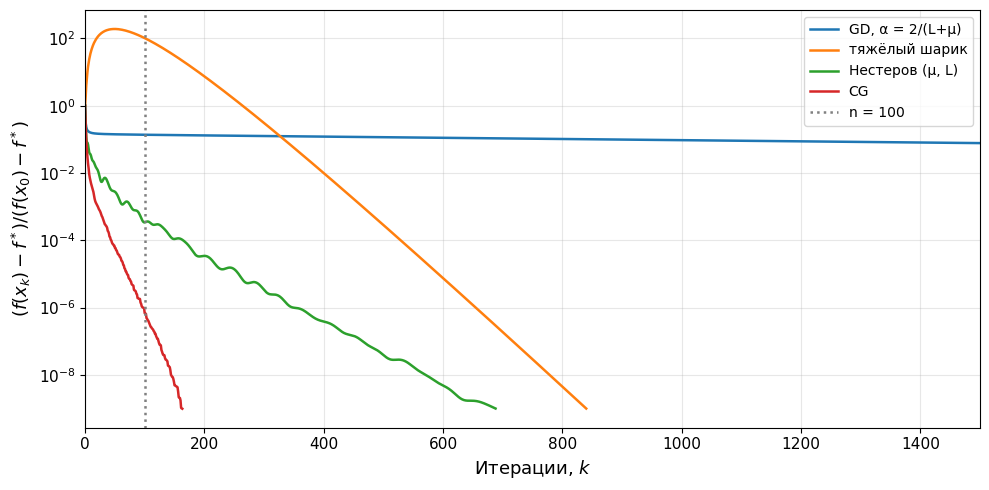

GD, α = 2/(L+μ)   : 46906
тяжёлый шарик     : 840
Нестеров (μ, L)   : 688
CG                : 163


In [7]:
rng = np.random.default_rng(1)
n_cg = 100; d_cg = np.logspace(0, 4, n_cg)
Qc, _ = np.linalg.qr(rng.standard_normal((n_cg, n_cg)))
Acg = Qc @ np.diag(d_cg) @ Qc.T; Acg = (Acg + Acg.T) / 2
bcg = Acg @ rng.standard_normal(n_cg)
fcg = lambda x: 0.5 * x @ Acg @ x - bcg @ x
gcg = lambda x: Acg @ x - bcg
Lc, muc = d_cg.max(), d_cg.min(); x0c = np.zeros(n_cg)
fcg_star = fcg(np.linalg.solve(Acg, bcg)); tol_c = 1e-9 * (fcg(x0c) - fcg_star)
ms_cg = [GradientDescent(ConstantStepSize(2 / (Lc + muc)), name="GD, α = 2/(L+μ)"),
         HeavyBall(*hb_params(Lc, muc),                    name="тяжёлый шарик"),
         Nesterov(Lc, mu=muc,                              name="Нестеров (μ, L)"),
         LinearCG(Acg, bcg,                                name="CG")]
for m in ms_cg:
    if isinstance(m, LinearCG): m.solve(x0c, fcg, gcg, tol=1e-12, max_iter=10 * n_cg)
    else: m.solve(x0c, fcg, gcg, tol=tol_c, max_iter=200000, fstar=fcg_star)
fig, ax = plt.subplots(figsize=(10, 5))
for m in ms_cg:
    k_ = first_hit(m, fcg_star, tol_c); fh = np.array(m.f_hist) - fcg_star
    ax.semilogy(np.maximum(fh[:int(k_) + 1] if np.isfinite(k_) else fh, 1e-18) / (fcg(x0c) - fcg_star), label=m.name)
ax.axvline(n_cg, color="gray", ls=":", label="n = 100")
ax.set_xlim(0, 1500); ax.set_xlabel("Итерации, $k$"); ax.set_ylabel(r"$(f(x_k) - f^*)/(f(x_0) - f^*)$"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
for m in ms_cg:
    print(f"{m.name:18s}: {first_hit(m, fcg_star, tol_c)}")

* CG быстрее ускоренных методов с точными $L$ и $\mu$ и на порядки быстрее GD, причём параметров у него нет.
* Граница в $n$ шагов верна в точной арифметике. В двойной точности ортогональность невязок теряется, и итераций нужно немного больше.

### 2.2. Обобщение на нелинейный случай


Для неквадратичной $f$ невязка заменяется градиентом, а точный шаг линейным поиском (правило Вольфа из недели 10):

**Нелинейный метод сопряжённых градиентов** ($g_k = \nabla f(x_k)$, $d_0 = -g_0$):
$$
\boxed{\begin{aligned}
x_{k+1} &= x_k + \alpha_kd_k, \quad \alpha_k \text{ по сильным условиям Вольфа},\\
d_{k+1} &= -g_{k+1} + \beta_{k+1}d_k,
\end{aligned}}
$$
где
$$
\beta^{FR}_k = \frac{\|g_k\|^2}{\|g_{k-1}\|^2},\qquad \beta^{PR}_k = \frac{\langle g_k, g_k - g_{k-1}\rangle}{\|g_{k-1}\|^2},\qquad \beta^{PR+}_k = \max(0, \beta^{PR}_k).
$$
На квадратичной функции с точным шагом все три формулы совпадают. FR гарантирует направление спуска при сильных условиях
Вольфа с $c_2 < \frac12$ (Аль-Баали). PR на практике быстрее: при маленьком шаге $g_k\approx g_{k-1}$, поэтому $\beta^{PR}\approx0$ и метод сам
сбрасывает накопленное направление.

**Задача.** Покажите, что на квадратичной функции с точным шагом $\beta^{FR}_k = \beta^{PR}_k$.

### 2.3. Связь с методом тяжёлого шарика

Заметим, что $p_{k-1} = \frac1{\alpha_{k-1}}(x_k - x_{k-1})$. Подставим это в шаг метода сопряжённых градиентов:
$$
x_{k+1} = x_k + \alpha_kp_k = x_k - \alpha_k\nabla f(x_k) + \alpha_k\beta_kp_{k-1} = x_k - \alpha_k\nabla f(x_k) + \frac{\alpha_k\beta_k}{\alpha_{k-1}}\,(x_k - x_{k-1}).
$$
Значит, любой метод сопряжённых градиентов (линейный, FR, PR) является методом тяжёлого шарика с переменными параметрами
$$
\boxed{\;\alpha^{HB}_k = \alpha^{CG}_k,\qquad \beta^{HB}_k = \frac{\alpha^{CG}_k\,\beta^{CG}_k}{\alpha^{CG}_{k-1}}\;}
$$
Разница только в том, как выбираются параметры: у тяжёлого шарика они постоянны и считаются по $L$ и $\mu$, а у сопряжённых
градиентов подбираются на каждом шаге (точным шагом или линейным поиском) и сами подстраиваются под задачу.

## 3. Логистическая регрессия: константы $L$ и $\mu$

Данные: датасет w8a из коллекции LIBSVM (классификация веб-страниц): $m = 49\,749$ объектов, $n = 300$ разреженных бинарных признаков,
метки $y_i\in\{\pm1\}$. Файл скачивается при первом запуске и читается стандартной функцией `load_svmlight_file`. Строки матрицы $A\in\mathbb R^{m\times n}$ обозначим $a_i^\top$.
$$
f(w) = \frac1m\sum_{i=1}^m\log\bigl(1 + e^{-y_ia_i^\top w}\bigr) + \frac\lambda2\|w\|^2 .
$$

**Утверждение 2 (константы логистической регрессии).**
$$
\nabla f(w) = -\frac1m A^\top\bigl(y\odot\sigma(-y\odot Aw)\bigr) + \lambda w,\qquad
\nabla^2f(w) = \frac1mA^\top D(w)A + \lambda I,\quad D = \operatorname{diag}\bigl(\sigma(z_i)(1 - \sigma(z_i))\bigr),\ z_i = a_i^\top w,
$$
где $\sigma(t) = 1/(1 + e^{-t})$. Поэтому
$$
\lambda I\ \preceq\ \nabla^2f(w)\ \preceq\ \Bigl(\frac{\|A\|_2^2}{4m} + \lambda\Bigr)I ,\qquad
L = \frac{\sigma_{\max}(A)^2}{4m} + \lambda,\quad \mu = \lambda .
$$
Верхняя оценка достигается при $w = 0$, нижняя в пределе $\|w\|\to\infty$ вдоль разделяющего направления, если оно есть.

Следствия:
* $L$ известна заранее и считается дёшево (одно сингулярное число). Глобальная оценка $\mu = \lambda$ пессимистична: в решении
  $\mu_{\rm loc} = \lambda_{\min}\bigl(\frac1mA^\top D(w^*)A\bigr) + \lambda$ может быть намного больше.
* При $\lambda = 0$ сильной выпуклости нет. Если данные линейно разделимы, минимума нет вообще: $f\to0$ вдоль разделяющего $w$.
  Если не разделимы, минимум есть, а $\mu_{\rm loc}$ зависит от того, насколько уверенно классифицированы объекты: $\sigma(1-\sigma)\approx e^{-|z_i|}$.

In [8]:
import os, urllib.request
from scipy.sparse.linalg import svds
from sklearn.datasets import load_svmlight_file

URL = "https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/binary/"
for name in ["w8a", "a9a"]:                       # a9a: ещё один датасет для самостоятельных экспериментов
    if not os.path.exists(name):
        urllib.request.urlretrieve(URL + name, name)

sig = lambda t: 0.5 * (1 + np.tanh(0.5 * t))          # устойчивая сигмоида
X, y = load_svmlight_file("w8a")
A_ = X.tocsr(); m_, n_ = A_.shape                       # y уже в {−1, +1}

def make_logreg(lam):
    def f(w):
        z = y * (A_ @ w); return np.mean(np.logaddexp(0, -z)) + lam / 2 * w @ w
    def grad(w):
        z = y * (A_ @ w); return -(A_.T @ (y * sig(-z))) / m_ + lam * w
    def hess(w):
        s_ = sig(A_ @ w); return (A_.T @ A_.multiply((s_ * (1 - s_))[:, None])).toarray() / m_ + lam * np.eye(n_)
    return f, grad, hess

smax2 = svds(A_, k=1, return_singular_vectors=False)[0] ** 2
print(f"w8a: m = {m_}, n = {n_}, доля ненулевых {A_.nnz / (m_ * n_):.1%};  σ_max(A)²/(4m) = {smax2 / (4 * m_):.3f}")
print(f"{'λ':>7s} {'L':>7s} {'μ = λ':>8s} {'κ = L/λ':>10s} {'‖w*‖':>7s}")
REF = {}
for lam in [1e-2, 1e-3, 1e-4, 1e-5]:
    f_, g_, h_ = make_logreg(lam)
    r = minimize(f_, np.zeros(n_), jac=g_, hess=h_, method="trust-exact", options=dict(gtol=1e-12, maxiter=1000))
    L_l = smax2 / (4 * m_) + lam
    REF[lam] = (r.x, r.fun, L_l)
    print(f"{lam:>7.0e} {L_l:>7.3f} {lam:>8.0e} {L_l / lam:>10.0f} {np.linalg.norm(r.x):>7.1f}")

w8a: m = 49749, n = 300, доля ненулевых 3.9%;  σ_max(A)²/(4m) = 0.661
      λ       L    μ = λ    κ = L/λ    ‖w*‖
  1e-02   0.671    1e-02         67     3.1
  1e-03   0.662    1e-03        662     6.9
  1e-04   0.661    1e-04       6613    16.0
  1e-05   0.661    1e-05      66121    34.5


Что видно:
* $L$ мало, но $\kappa = L/\lambda$ растёт как $1/\lambda$, и задача быстро становится плохо обусловленной;
* чем меньше $\lambda$, тем дальше решение от нуля ($\|w^*\|$ растёт), то есть тем дальше методу идти от стартовой точки.

In [9]:
lam0 = 1e-4
w_s, f_s, L_l = REF[lam0]

## 4. Методы на логистической регрессии

Берём $\lambda = 10^{-4}$. Сначала сравним между собой варианты нелинейных сопряжённых градиентов, затем две формы метода
Нестерова, и в конце лучших представителей каждого семейства вместе с GD и тяжёлым шариком.

### 4.1. Сопряжённые градиенты: FR, PR, PR$+$

CG-FR  : итераций 62, вызовов f 220, вызовов ∇f 250
CG-PR  : итераций 48, вызовов f 173, вызовов ∇f 193
CG-PR+ : итераций 46, вызовов f 178, вызовов ∇f 192


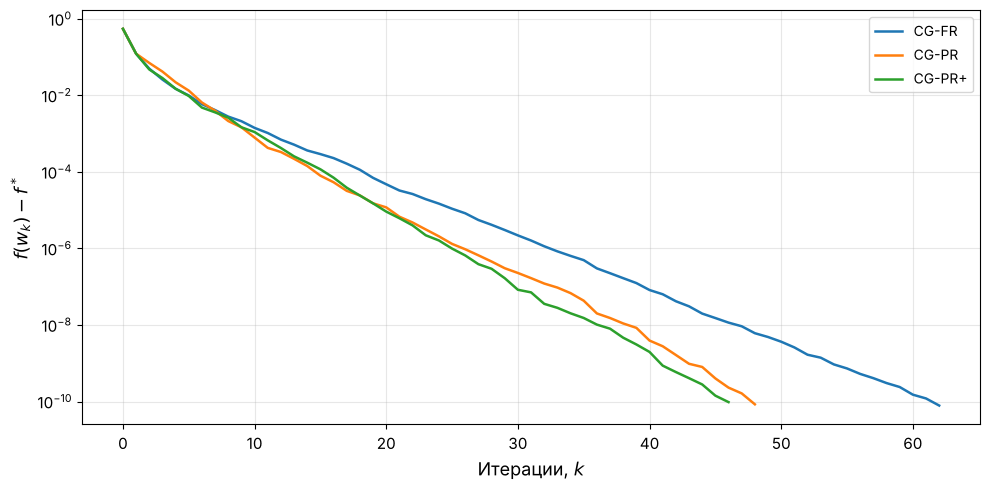

In [10]:
f, grad, _ = make_logreg(lam0); x0 = np.zeros(n_); tol = 1e-10
methods_cg = [ConjugateGradients(b, name=f"CG-{b}") for b in ["FR", "PR", "PR+"]]
for m in methods_cg:
    m.solve(x0, f, grad, tol=tol, max_iter=20000, fstar=f_s)
fig, ax = plt.subplots(figsize=(10, 5))
for m in methods_cg:
    ax.semilogy(np.maximum(np.array(m.f_hist) - f_s, 1e-16), label=m.name)
ax.set_xlabel("Итерации, $k$"); ax.set_ylabel(r"$f(w_k) - f^*$"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for m in methods_cg:
    print(f"{m.name:7s}: итераций {first_hit(m, f_s, tol)}, вызовов f {m.history[-1][2]}, вызовов ∇f {m.history[-1][3]}")

### 4.2. Метод Нестерова: выпуклая и сильно выпуклая формы

Нестеров, β_k = k/(k+3)       : 10307
Нестеров, μ = λ               : 852


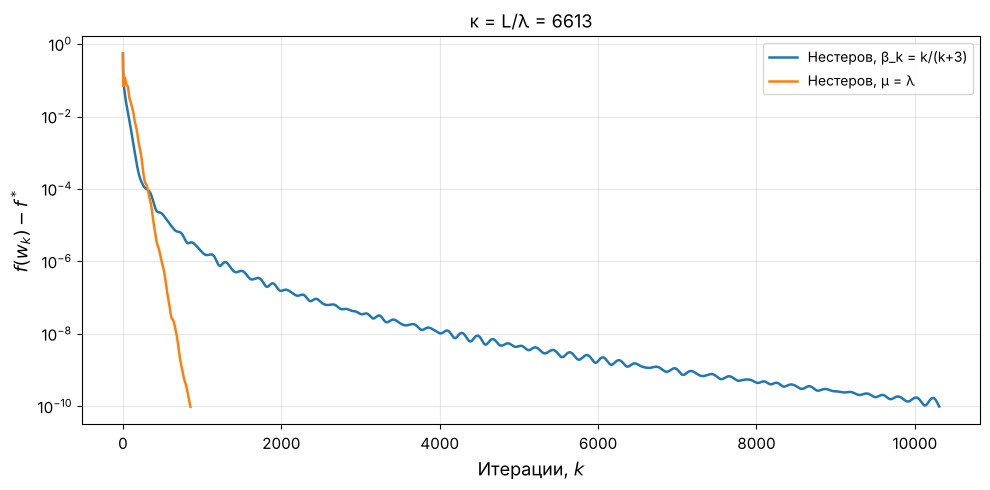

In [11]:
methods_n = [Nesterov(L_l,            name="Нестеров, β_k = k/(k+3)"),
             Nesterov(L_l, mu=lam0,   name="Нестеров, μ = λ")]
for m in methods_n:
    m.solve(x0, f, grad, tol=tol, max_iter=100000, fstar=f_s)
fig, ax = plt.subplots(figsize=(10, 5))
for m in methods_n:
    ax.semilogy(np.maximum(np.array(m.f_hist) - f_s, 1e-16), label=m.name)
ax.set_xlabel("Итерации, $k$"); ax.set_ylabel(r"$f(w_k) - f^*$"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f"κ = L/λ = {L_l / lam0:.0f}"); plt.tight_layout(); plt.show()
for m in methods_n:
    print(f"{m.name:30s}: {first_hit(m, f_s, tol)}")

* Выпуклая форма не использует сильную выпуклость.
* Сильно выпуклая форма требует $\mu$. Здесь оценка $\mu = \lambda$ точна, и сильно выпуклая форма быстрее выпуклой, но при большом $\kappa$
  ускорение всё равно даётся дорого.

### 4.3. Лучшие методы вместе

метод                       итераций  вызовов f  вызовов ∇f
GD, 1/L                        44471          0       44471
тяжёлый шарик (μ = λ)            472          0         472
Нестеров, μ = λ                  852          0         852
CG-PR+                            46        178         192


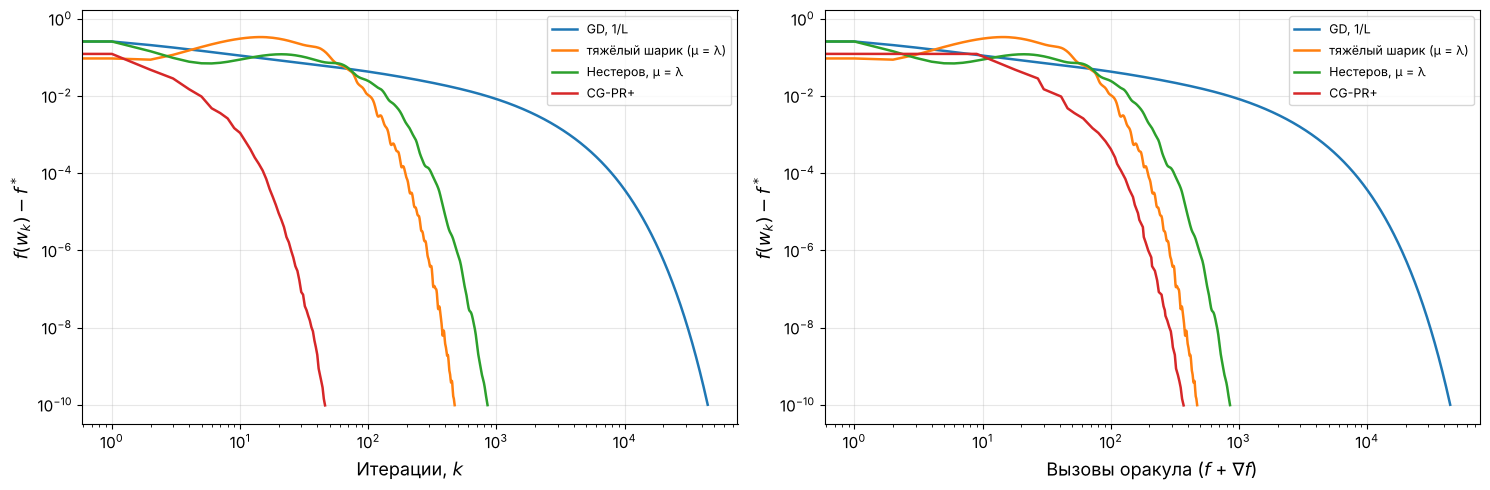

In [12]:
best_cg = min(methods_cg, key=lambda m: first_hit(m, f_s, tol))
best_n = min(methods_n[:2], key=lambda m: first_hit(m, f_s, tol))       # без оракула
gd = GradientDescent(ConstantStepSize(1 / L_l), name="GD, 1/L")
hb = HeavyBall(*hb_params(L_l, lam0), name="тяжёлый шарик (μ = λ)")
for m in [gd, hb]:
    m.solve(x0, f, grad, tol=tol, max_iter=100000, fstar=f_s)
final = [gd, hb, best_n, best_cg]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for m in final:
    fh = np.maximum(np.array(m.f_hist) - f_s, 1e-16)
    axes[0].semilogy(fh, label=m.name)
    axes[1].semilogy([r[2] + r[3] for r in m.history], fh, label=m.name)
axes[0].set_xscale("log"); axes[0].set_xlabel("Итерации, $k$"); axes[1].set_xscale("log")
axes[1].set_xlabel(r"Вызовы оракула ($f$ + $\nabla f$)")
for ax in axes: ax.set_ylabel(r"$f(w_k) - f^*$"); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print(f"{'метод':26s} {'итераций':>9s} {'вызовов f':>10s} {'вызовов ∇f':>11s}")
for m in final:
    print(f"{m.name:26s} {first_hit(m, f_s, tol):>9} {m.history[-1][2]:>10} {m.history[-1][3]:>11}")

* Сравнивать стоит не только итерации, но и вызовы оракула: линейный поиск по условиям Вольфа тратит несколько вычислений $f$ и
  $\nabla f$ на итерацию, а ускоренным методам хватает одного градиента.
* CG подстраивается под спектр гессиана и не зависит от неточной оценки $L$, поэтому выигрывает у всех методов с постоянными параметрами.

### 4.4. Когда Флетчер–Ривс застревает

При точном линейном поиске ($c_2 = 0.1$) FR и PR ведут себя похоже. Возьмём ту же задачу, но грубый линейный поиск ($c_2 = 0.9$).
Кроме $f(x_k) - f^*$ будем смотреть на косинус угла между направлением и антиградиентом
$$
\cos\theta_k = \frac{-\langle\nabla f(x_k), d_k\rangle}{\|\nabla f(x_k)\|\,\|d_k\|} .
$$

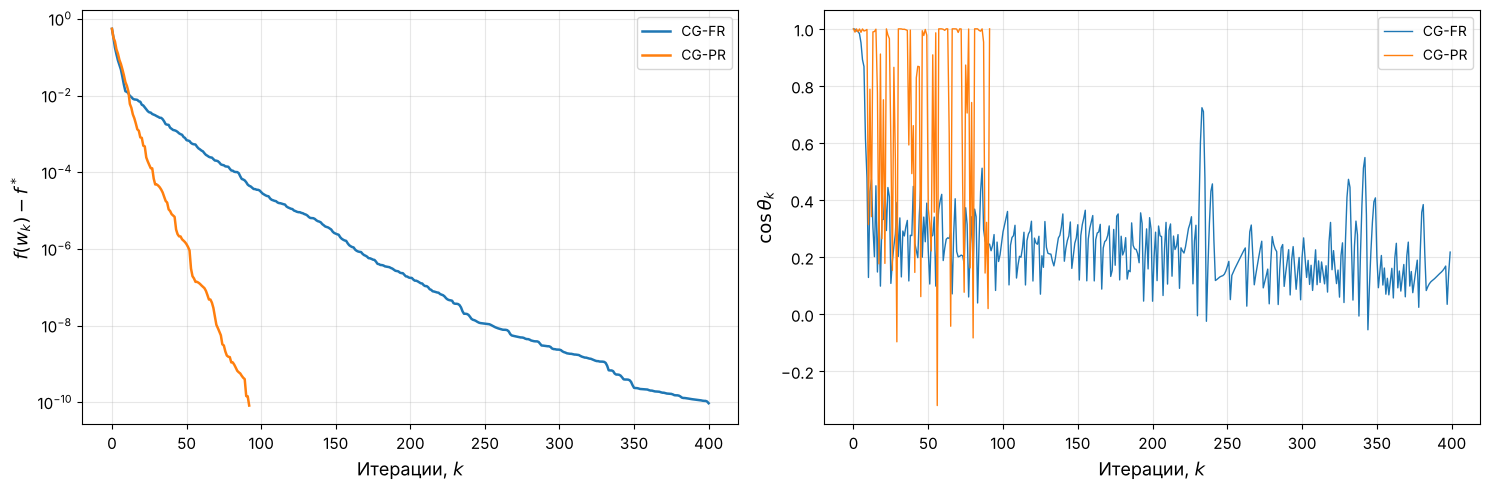

In [13]:
ms_w = [ConjugateGradients("FR", c2=0.9, name="CG-FR"), ConjugateGradients("PR", c2=0.9, name="CG-PR")]
for m in ms_w:
    m.solve(x0, f, grad, tol=tol, max_iter=5000, fstar=f_s)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for m in ms_w:
    axes[0].semilogy(np.maximum(np.array(m.f_hist) - f_s, 1e-16), label=m.name)
    axes[1].plot(m.cos, label=m.name, lw=1)
axes[0].set_xlabel("Итерации, $k$"); axes[0].set_ylabel(r"$f(w_k) - f^*$"); axes[0].grid(alpha=0.3); axes[0].legend()
axes[1].set_xlabel("Итерации, $k$"); axes[1].set_ylabel(r"$\cos\theta_k$"); axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout(); plt.show()

* Направления FR почти перпендикулярны антиградиенту: $\cos\theta_k$ большую часть времени мал. Метод застревает: маленький шаг даёт
  $g_k\approx g_{k-1}$, коэффициент $\beta^{FR}_k\approx1$, и следующее направление повторяет предыдущее плохое направление.
* У PR в той же ситуации $\beta^{PR}_k\approx0$, направление само сбрасывается к антиградиенту, и $\cos\theta_k$ остаётся близким к единице.
* При $c_2 = 0.9$ сильные условия Вольфа уже не гарантируют спуск, и у обоих методов встречаются $\cos\theta_k < 0$. На таких
  итерациях линейный поиск не находит шага, точка почти не сдвигается, и метод теряет итерацию.

Вопрос: как заставить FR (и вообще метод с памятью) выбраться из такой ситуации, не меняя формулу для $\beta$?

## 5. Адаптивность по $\mu$

Сильно выпуклая форма метода Нестерова быстра, только если $\mu$ известно точно, а гарантированная оценка часто занижена.
Вопрос полной адаптивности по $\mu$ (ускоренный метод с оптимальной скоростью без знания $\mu$) пока не решён. Ниже две эвристики,
которые подбирают непосредственно $\mu$ по ходу работы.

### 5.1. Локальный vs глобальный $\mu$

Глобальная оценка $\mu = \lambda$ гарантирована всюду, а локальная $\mu_{\rm loc} = \lambda_{\min}(\nabla^2f(w^*))$ описывает кривизну вблизи решения, где метод
проводит большую часть времени. На полном w8a они совпадают: признаки являются one-hot кодировкой категорий, поэтому столбцы $A$
линейно зависимы, у $A^\top A$ есть точно нулевые собственные значения, и вдоль этих направлений кривизну создаёт только регуляризатор.

Оставим 10 самых частых признаков. Столбцы становятся линейно независимыми, и данные сами создают кривизну во всех направлениях.

глобальная оценка μ = λ = 1e-06,  κ = 3.0e+05
локальная μ_loc = λmin(∇²f(w*)) = 2.06e-03,  κ_loc = 144


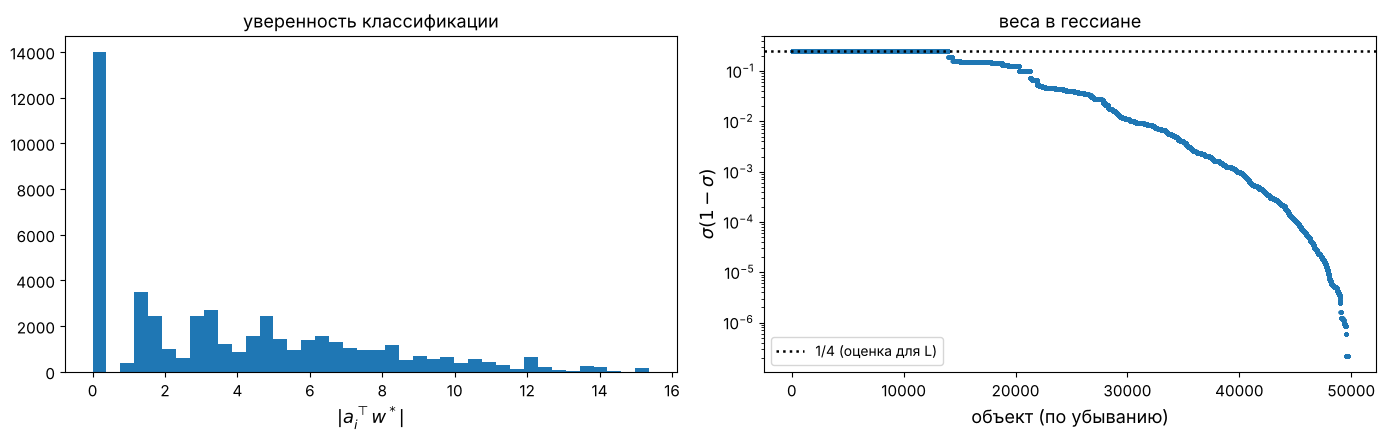

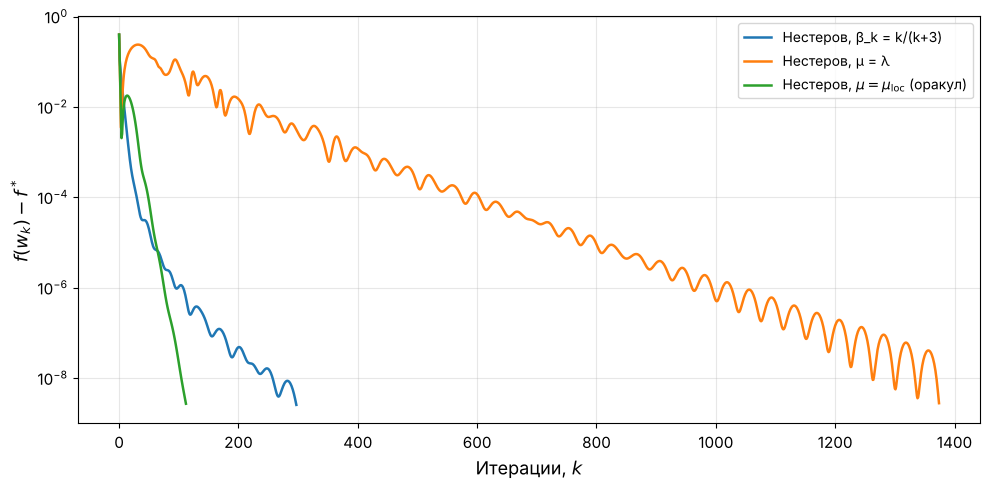

In [14]:
freq = np.asarray((A_ != 0).sum(0)).ravel()
Ak = A_[:, np.argsort(-freq)[:10]]; nk = Ak.shape[1]           # 10 самых частых признаков
lam_k = 1e-6

def make_logreg_A(A, lam):
    m = A.shape[0]
    f = lambda w: np.mean(np.logaddexp(0, -y * (A @ w))) + lam / 2 * w @ w
    g = lambda w: -(A.T @ (y * sig(-y * (A @ w)))) / m + lam * w
    h = lambda w: (A.T @ A.multiply((sig(A @ w) * (1 - sig(A @ w)))[:, None])).toarray() / m + lam * np.eye(A.shape[1])
    return f, g, h

fk, gk, hk = make_logreg_A(Ak, lam_k)
rk = minimize(fk, np.zeros(nk), jac=gk, hess=hk, method="trust-exact", options=dict(gtol=1e-13, maxiter=2000))
wk_s, fk_s = rk.x, rk.fun
Lk = np.linalg.norm(Ak.toarray(), 2) ** 2 / (4 * m_) + lam_k
mu_k = np.linalg.eigvalsh(hk(wk_s))[0]
print(f"глобальная оценка μ = λ = {lam_k:.0e},  κ = {Lk / lam_k:.1e}")
print(f"локальная μ_loc = λmin(∇²f(w*)) = {mu_k:.2e},  κ_loc = {Lk / mu_k:.0f}")

z_s = Ak @ wk_s; dd = sig(z_s) * (1 - sig(z_s))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(np.abs(z_s), bins=40); axes[0].set_xlabel(r"$|a_i^\top w^*|$"); axes[0].set_title("уверенность классификации")
axes[1].semilogy(np.sort(dd)[::-1], "o", ms=2); axes[1].axhline(0.25, color="k", ls=":", label="1/4 (оценка для L)")
axes[1].set_xlabel("объект (по убыванию)"); axes[1].set_ylabel(r"$\sigma(1-\sigma)$"); axes[1].legend(); axes[1].set_title("веса в гессиане")
plt.tight_layout(); plt.show()

x0k = np.zeros(nk); tol_k = 1e-8 * abs(fk_s)
methods_k = [Nesterov(Lk,           name="Нестеров, β_k = k/(k+3)"),
             Nesterov(Lk, mu=lam_k, name="Нестеров, μ = λ"),
             Nesterov(Lk, mu=mu_k,  name=r"Нестеров, $\mu = \mu_{\mathrm{loc}}$ (оракул)")]
for m in methods_k:
    m.solve(x0k, fk, gk, tol=tol_k, max_iter=100000, fstar=fk_s)
fig, ax = plt.subplots(figsize=(10, 5))
for m in methods_k:
    ax.semilogy(np.maximum(np.array(m.f_hist) - fk_s, 1e-16), label=m.name)
ax.set_xlabel("Итерации, $k$"); ax.set_ylabel(r"$f(w_k) - f^*$"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

* Локальная $\mu$ на порядки больше глобальной оценки $\lambda$: кривизну вблизи решения создают сами данные, а $\lambda$ к ней почти ничего не добавляет.
* Поэтому метод, настроенный на $\mu = \lambda$, работает с лишней осторожностью, а метод с настоящим $\mu_{\rm loc}$ намного быстрее. Но $\mu_{\rm loc}$
  заранее неизвестна: чтобы её посчитать, нужно знать решение.
* Распределение $\sigma(1-\sigma)$ показывает, откуда берётся кривизна: уверенно классифицированные объекты (с большим $|z_i|$) почти не вкладываются в гессиан.

Дальше на этой задаче оцениваем $\mu$ по ходу работы.

### 5.2. NAG-free

Для $\mu$-сильно выпуклой функции с $L$-липшицевым градиентом
$$
\mu\|x - y\|\le\|\nabla f(x) - \nabla f(y)\|\le L\|x - y\| ,
$$
поэтому секущая кривизна вдоль пройденного шага $c_{t+1} = \frac{\|\nabla f(x_{t+1}) - \nabla f(x_t)\|}{\|x_{t+1} - x_t\|}$ лежит в $[\mu, L]$ и является оценкой $\mu$ сверху.
Траектория ускоренного метода со временем выстраивается вдоль пологих направлений, поэтому бегущий минимум $m_t = \min_{s\le t}c_s$
сходится к нужной величине. Метод NAG-free (Cavalcanti, Lessard, Wilson, 2025) подставляет $m_t$ в формулу для $\beta$.

**Метод NAG-free** ($y_0 = x_0$, $m_0$ по паре близких точек):
$$
\boxed{\begin{aligned}
y_{t+1} &= x_t - \tfrac1L\nabla f(x_t),\\
\beta_t &= \frac{\sqrt L - \sqrt{m_t}}{\sqrt L + \sqrt{m_t}},\qquad x_{t+1} = y_{t+1} + \beta_t\,(y_{t+1} - y_t),\\
m_{t+1} &= \min\Bigl\{m_t,\ \frac{\|\nabla f(x_{t+1}) - \nabla f(x_t)\|}{\|x_{t+1} - x_t\|}\Bigr\}.
\end{aligned}}
$$
Оба градиента в формуле для $c_{t+1}$ метод вычисляет и так, поэтому оценка обходится без дополнительных вызовов оракула. Оценка
сверху даёт заниженный коэффициент инерции, то есть метод сначала работает почти как GD и включает ускорение по мере того, как
убеждается в пологости задачи.

Это тоже эвристика: глобальных гарантий оптимальной скорости у NAG-free нет. Авторы доказывают только локальную скорость
сходимости, причём для модификаций алгоритма (например, с осторожным уменьшением оценки $m_{t+1} = \min\{c_{t+1}, m_t/\gamma\}$).

### 5.3. $\mu$ как константа Липшица сопряжённой функции

В работе Malitsky, Mishchenko, *Adaptive Gradient Descent without Descent* (ICML 2020, arXiv:1910.09529) предложен ещё и ускоренный
вариант (Algorithm 2), где адаптивно оцениваются обе константы. Идея оценки $\mu$ такая. Если $f$ $\mu$-сильно выпукла, то сопряжённая
функция $f^*$ имеет $\frac1\mu$-липшицев градиент, и $\nabla f^*(\nabla f(x)) = x$. Значит, $\mu$ можно оценивать так же, как $L$, только для $f^*$
в точках $p^k = \nabla f(x^k)$: локальная константа Липшица $\nabla f^*$ равна $\frac{\|x^k - x^{k-1}\|}{\|\nabla f(x^k) - \nabla f(x^{k-1})\|}$, а обратная к ней величина и есть оценка $\mu$.
Шаг $\lambda_k$ оценивается правилом AdGD из недели 10, оценка $\Lambda_k$ для $\mu$ строится симметрично.

**Ускоренный AdGD** (Algorithm 2; $\theta_0 = \Theta_0 = +\infty$, $y^1 = x^1 = x^0 - \lambda_0\nabla f(x^0)$):
$$
\boxed{\begin{aligned}
\lambda_k &= \min\Bigl\{\sqrt{1 + \tfrac{\theta_{k-1}}2}\,\lambda_{k-1},\ \frac{\|x^k - x^{k-1}\|}{2\|\nabla f(x^k) - \nabla f(x^{k-1})\|}\Bigr\},\\
\Lambda_k &= \min\Bigl\{\sqrt{1 + \tfrac{\Theta_{k-1}}2}\,\Lambda_{k-1},\ \frac{\|\nabla f(x^k) - \nabla f(x^{k-1})\|}{2\|x^k - x^{k-1}\|}\Bigr\},\\
\beta_k &= \frac{\sqrt{1/\lambda_k} - \sqrt{\Lambda_k}}{\sqrt{1/\lambda_k} + \sqrt{\Lambda_k}},\\
y^{k+1} &= x^k - \lambda_k\nabla f(x^k),\qquad x^{k+1} = y^{k+1} + \beta_k\,(y^{k+1} - y^k),\\
\theta_k &= \lambda_k/\lambda_{k-1},\qquad \Theta_k = \Lambda_k/\Lambda_{k-1}.
\end{aligned}}
$$
Здесь $1/\lambda_k$ играет роль $L$, а $\Lambda_k$ роль $\mu$. Знать не нужно ни $L$, ни $\mu$. Авторы прямо пишут, что теоретических гарантий
для этого варианта у них нет: это эвристика.

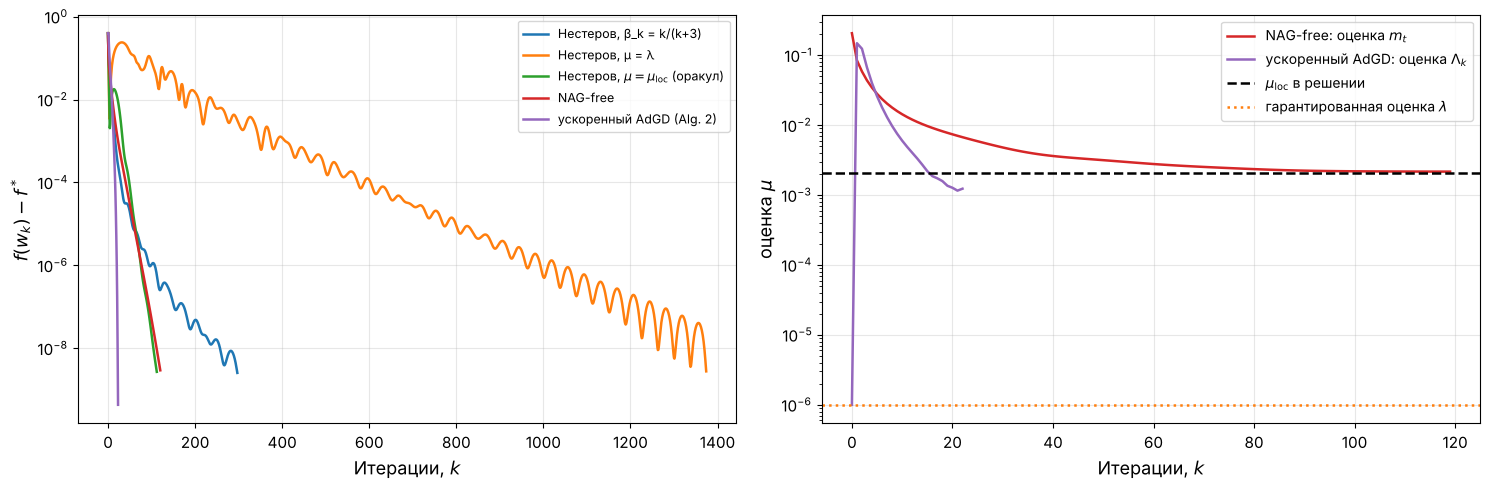

In [15]:
nf = NAGFree(Lk, name="NAG-free")
nf.solve(x0k, fk, gk, tol=tol_k, max_iter=100000, fstar=fk_s)
aa = AdaptiveAcceleratedGD(name="ускоренный AdGD (Alg. 2)")
aa.solve(x0k, fk, gk, tol=tol_k, max_iter=100000, fstar=fk_s)
ms_ad = methods_k + [nf, aa]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for m in ms_ad:
    axes[0].semilogy(np.maximum(np.array(m.f_hist) - fk_s, 1e-16), label=m.name)
axes[0].set_xlabel("Итерации, $k$"); axes[0].set_ylabel(r"$f(w_k) - f^*$"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=9)
axes[1].semilogy(nf.m_hist, color="C3", label=r"NAG-free: оценка $m_t$")
axes[1].semilogy(aa.Lam_hist, color="C4", label=r"ускоренный AdGD: оценка $\Lambda_k$")
axes[1].axhline(mu_k, color="k", ls="--", label=r"$\mu_{\rm loc}$ в решении")
axes[1].axhline(lam_k, color="C1", ls=":", label=r"гарантированная оценка $\lambda$")
axes[1].set_xlabel("Итерации, $k$"); axes[1].set_ylabel("оценка $\\mu$"); axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout(); plt.show()

## Итоги

Пройденные методы:
* градиентный спуск с постоянным шагом $\frac1L$ и $\frac2{L+\mu}$;
* метод тяжёлого шарика (Поляк);
* метод Нестерова в выпуклой ($\beta_k = \frac k{k+3}$) и сильно выпуклой ($\beta = \frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}$) формах;
* метод сопряжённых градиентов для квадратичной функции и его нелинейные варианты FR, PR, PR$+$ (как метод тяжёлого шарика с адаптивными параметрами);
* эвристики адаптивного подбора $\mu$: NAG-free и ускоренный AdGD Малицкого и Мищенко.